In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data analysis and visualization of last 365 days

In [13]:
df365 = pd.read_csv('cleaned_GothatarLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,54.360528,%,2025-10-12 06:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,06:45:00
1,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,51.080333,%,2025-10-12 07:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,07:45:00
2,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,42.371125,%,2025-10-12 08:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,08:45:00
3,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,40.663944,%,2025-10-12 09:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,09:45:00
4,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,37.478667,%,2025-10-12 10:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,49.635333,%,2025-11-23 23:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-23,23:45:00
996,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,49.816833,%,2025-11-24 00:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-24,00:45:00
997,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,49.766833,%,2025-11-24 01:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-24,01:45:00
998,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,50.080833,%,2025-11-24 02:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-24,02:45:00


In [14]:
df365['date'].unique()

<ArrowStringArray>
['2025-10-12', '2025-10-13', '2025-10-14', '2025-10-15', '2025-10-16',
 '2025-10-17', '2025-10-18', '2025-10-19', '2025-10-20', '2025-10-21',
 '2025-10-22', '2025-10-23', '2025-10-24', '2025-10-25', '2025-10-26',
 '2025-10-27', '2025-10-28', '2025-10-29', '2025-10-30', '2025-10-31',
 '2025-11-01', '2025-11-02', '2025-11-03', '2025-11-04', '2025-11-05',
 '2025-11-06', '2025-11-07', '2025-11-08', '2025-11-09', '2025-11-10',
 '2025-11-11', '2025-11-12', '2025-11-13', '2025-11-14', '2025-11-15',
 '2025-11-16', '2025-11-17', '2025-11-18', '2025-11-19', '2025-11-20',
 '2025-11-21', '2025-11-22', '2025-11-23', '2025-11-24']
Length: 44, dtype: str

In [15]:
# 1. Load hourly data observations
hourly = df365

# Ensure date and relative humidity values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [16]:
# 2-3. Aggrigate available hourly relativehumidity values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        relativehumidity_daily_mean=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [17]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [18]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["relativehumidity_daily_mean"].isna(), "fill_method"] = "missing_long_gap"

In [19]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["relativehumidity_daily_mean"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["relativehumidity_daily_mean"]
            right_value = daily.iloc[last_pos + 1]["relativehumidity_daily_mean"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["relativehumidity_daily_mean"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "relativehumidity_daily_mean"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [20]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [22]:
daily

,date,relativehumidity_daily_mean,hourly_observation_count,fill_method
0,2025-10-12,2025-10-12,18,observed
1,2025-10-13,2025-10-13,24,observed
2,2025-10-14,2025-10-14,24,observed
3,2025-10-15,2025-10-15,24,observed
4,2025-10-16,2025-10-16,24,observed
5,2025-10-17,2025-10-17,24,observed
6,2025-10-18,2025-10-18,24,observed
7,2025-10-19,2025-10-19,24,observed
8,2025-10-20,2025-10-20,21,observed
9,2025-10-21,2025-10-21,24,observed


In [23]:
daily.columns

Index(['date', 'relativehumidity_daily_mean', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_11601/3061540063.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


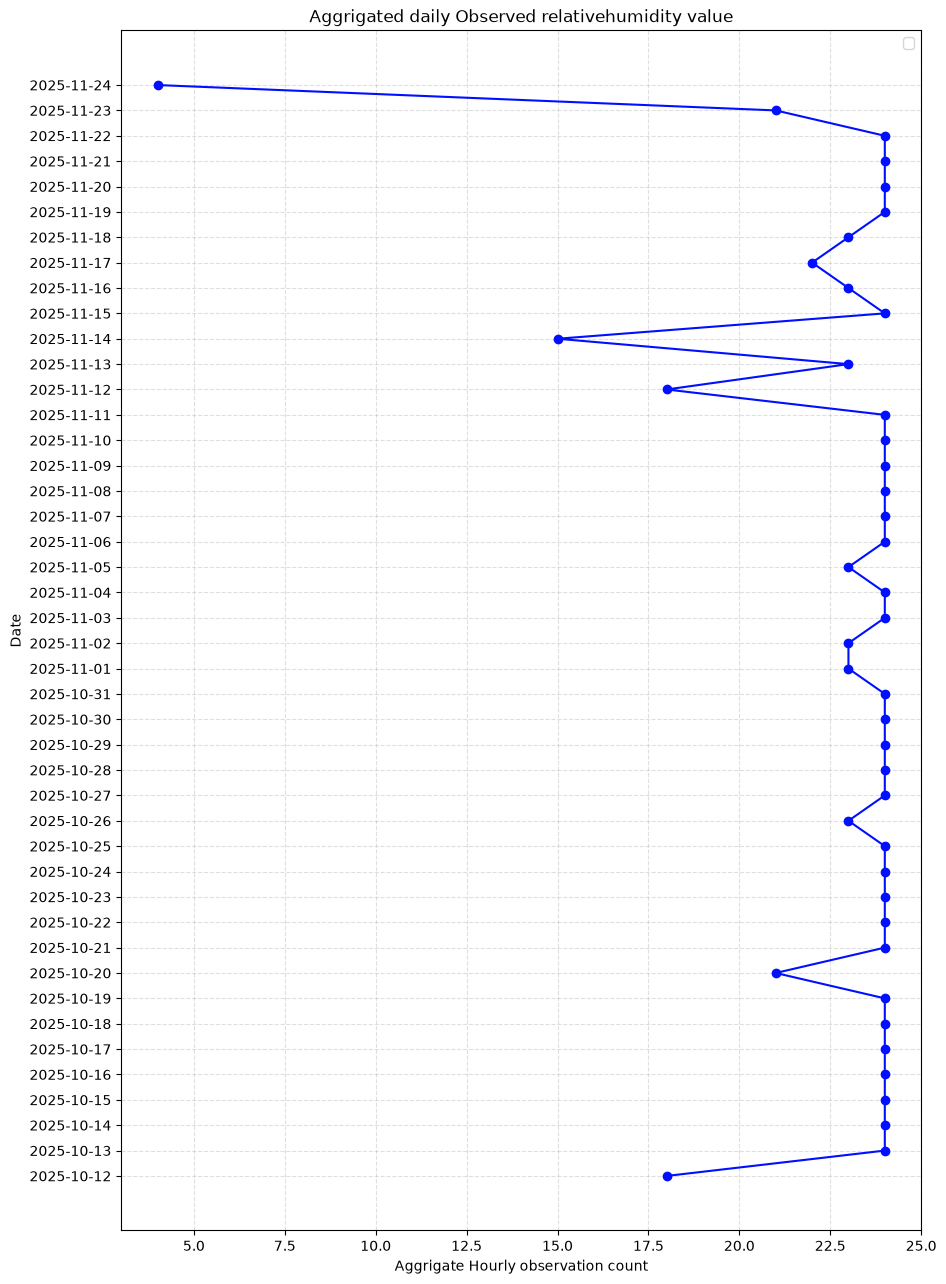

In [24]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 30 days

In [25]:
df30 = pd.read_csv('cleaned_GothatarLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,59.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,50.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,44.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,43.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
709,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
710,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,55.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
711,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
712,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,57.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [26]:
df30['date'].unique

<bound method Series.unique of 0      2026-09-12
1      2026-09-12
2      2026-09-12
3      2026-09-12
4      2026-09-12
          ...    
709    2026-10-12
710    2026-10-12
711    2026-10-12
712    2026-10-12
713    2026-10-12
Name: date, Length: 714, dtype: str>

In [27]:
# 1. Load hourly data observations
hourly = df30

# Ensure date and Relativehumidity have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [28]:
# 2-3. Aggrigate available hourly RElativehumidity to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        Relativehumidity_daily_mean=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [29]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [31]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["Relativehumidity_daily_mean"].isna(), "fill_method"] = "missing_long_gap"

In [32]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["Relativehumidity_daily_mean"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["Relativehumidity_daily_mean"]
            right_value = daily.iloc[last_pos + 1]["Relativehumidity_daily_mean"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["Relativehumidity_daily_mean"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "Relativehumidity_daily_mean"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [33]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [34]:
daily

,date,Relativehumidity_daily_mean,hourly_observation_count,fill_method
0,2026-09-12,2026-09-12,18,observed
1,2026-09-13,2026-09-13,24,observed
2,2026-09-14,2026-09-14,24,observed
3,2026-09-15,2026-09-15,24,observed
4,2026-09-16,2026-09-16,24,observed
5,2026-09-17,2026-09-17,24,observed
6,2026-09-18,2026-09-18,24,observed
7,2026-09-19,2026-09-19,24,observed
8,2026-09-20,2026-09-20,24,observed
9,2026-09-21,2026-09-21,24,observed


In [35]:
daily.columns

Index(['date', 'Relativehumidity_daily_mean', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_11601/278291562.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


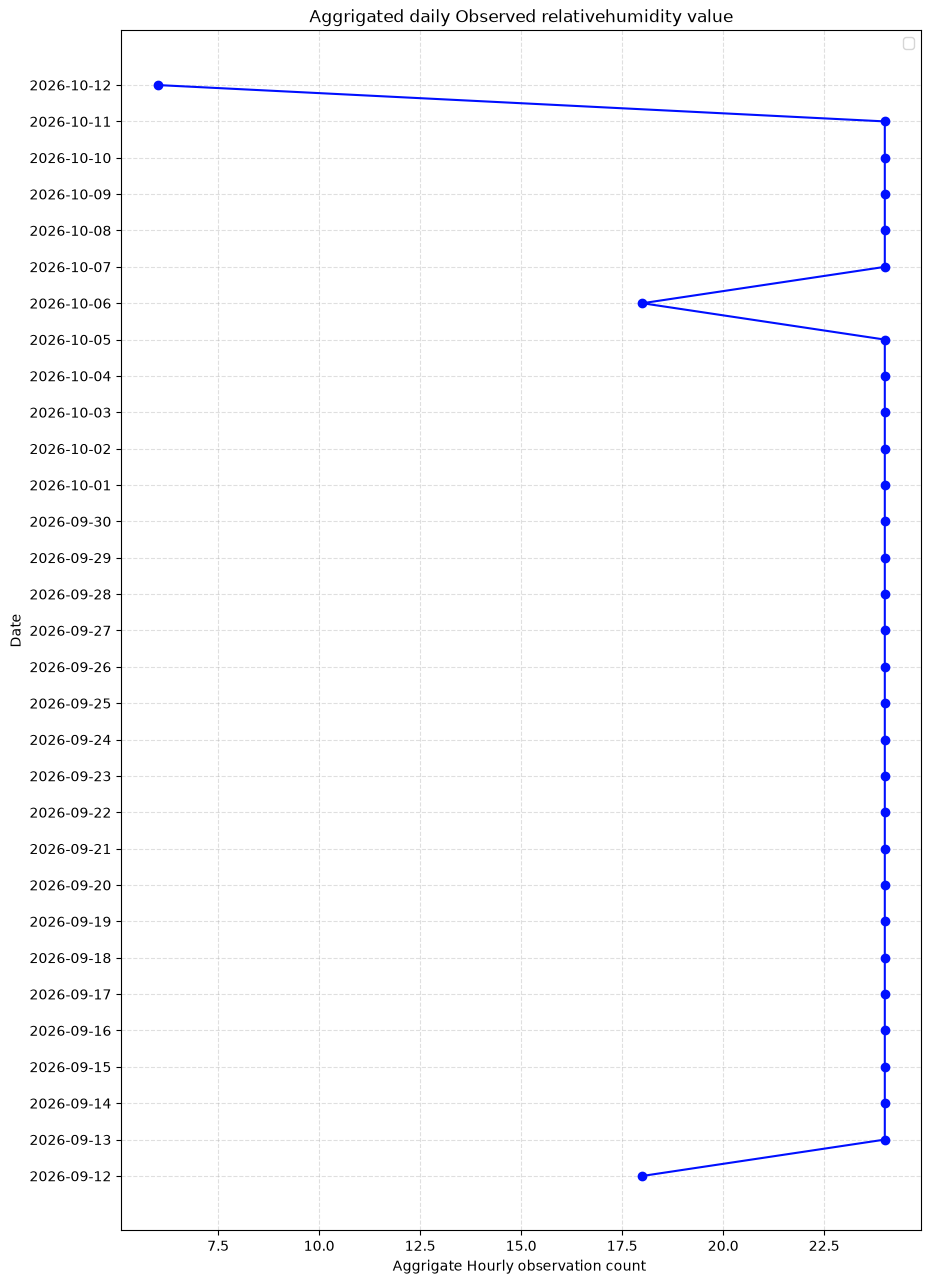

In [36]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [37]:
df7 = pd.read_csv('cleaned_GothatarLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,53.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,52.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,51.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,44.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
158,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,55.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
159,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
160,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,57.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [38]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

In [43]:
# 1. Load hourly data observations
hourly = df7

# Ensure date and Relativehumidity have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [44]:
# 2-3. Aggrigate available hourly RElativehumidity to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        Relativehumidity_daily_mean=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [45]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [46]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["Relativehumidity_daily_mean"].isna(), "fill_method"] = "missing_long_gap"

In [47]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["Relativehumidity_daily_mean"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["Relativehumidity_daily_mean"]
            right_value = daily.iloc[last_pos + 1]["Relativehumidity_daily_mean"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["Relativehumidity_daily_mean"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "Relativehumidity_daily_mean"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [48]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [49]:
daily

,date,Relativehumidity_daily_mean,hourly_observation_count,fill_method
0,2026-10-05,2026-10-05,18,observed
1,2026-10-06,2026-10-06,18,observed
2,2026-10-07,2026-10-07,24,observed
3,2026-10-08,2026-10-08,24,observed
4,2026-10-09,2026-10-09,24,observed
5,2026-10-10,2026-10-10,24,observed
6,2026-10-11,2026-10-11,24,observed
7,2026-10-12,2026-10-12,6,observed


In [50]:
daily.columns

Index(['date', 'Relativehumidity_daily_mean', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_11601/393496516.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


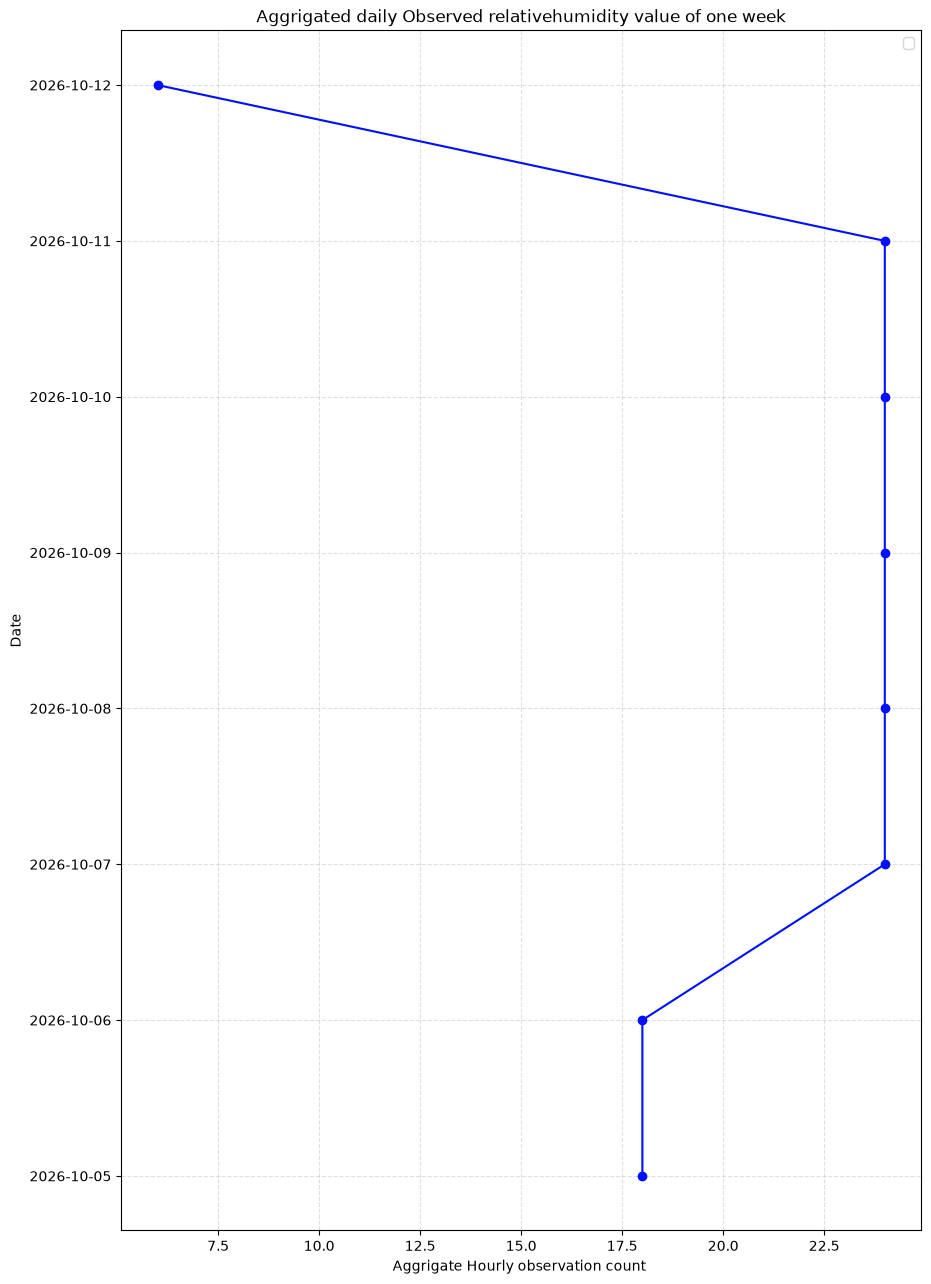

In [52]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours